# 02 · Baseline de 3D Gaussian Splatting (gsplat)

Este notebook entrena 3DGS sobre Truck en dos condiciones de referencia, que acotan todo el
experimento:

| Condición | Imágenes de entrenamiento | Para qué sirve |
|---|---|---|
| **original** (baseline) | las 21 vistas originales (979 × 546) | mejor calidad alcanzable con estas vistas |
| **control** (`control_256x512`) | cada vista se reduce a la rejilla SPC (256 × 512) y se vuelve a ampliar, sin SPC | pérdida debida **solo** al remuestreo; cota superior de cualquier condición SPC |

**Qué se mide:** después de entrenar, se renderizan las 3 vistas de **prueba** (que el modelo no
vio) y se comparan con las imágenes **originales** mediante PSNR, SSIM y LPIPS-VGG. En la
condición control, por lo tanto, la comparación se hace contra la imagen original y no contra la
remuestreada.

Las corridas se lanzan con `scripts/train_gsplat.sh`, el mismo script que usa el experimento
completo. Si una corrida ya existe, no se repite: se leen sus métricas.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

ESCENA = "truck"
SEMILLA = 449
CONDICIONES = ["original", "control_256x512"]


def ejecutar(cmd):
    """Ejecuta un comando en la raíz del repo y muestra el final de su salida."""
    print("$", " ".join(cmd))
    r = subprocess.run(cmd, cwd=RAIZ, capture_output=True, text=True)
    print(r.stdout[-1500:])
    if r.returncode != 0:
        print(r.stderr[-3000:])
        raise RuntimeError(f"Falló el comando (código {r.returncode})")

## 1. Memoria disponible y resolución

La GPU (RTX 4060, 8 GB) comparte memoria con Windows (unos 0.9 GB en uso). Con 21 vistas a
979 × 546, la corrida de prueba de 3000 iteraciones reservó 2.0 GiB en PyTorch (pico de 2.6 GB
en `nvidia-smi`, incluido el uso de Windows); los valores de cada corrida quedan en la columna
`mem_max_GiB`. Por eso se entrena a resolución completa (`FACTOR = 1`). Si la memoria libre fuera menor que 3 GB, la
celda propone `FACTOR = 2` (mitad de resolución), que reduce la memoria aproximadamente a la
cuarta parte.

In [2]:
libre, total = torch.cuda.mem_get_info()
print(f"Memoria GPU libre: {libre / 2**30:.2f} GiB de {total / 2**30:.2f} GiB")
FACTOR = 1 if libre / 2**30 >= 3 else 2
print("FACTOR de resolución elegido:", FACTOR)

Memoria GPU libre: 6.93 GiB de 8.00 GiB
FACTOR de resolución elegido: 1


## 2. Crear las condiciones (si no existen)

`src/make_dataset.py` crea `data/conditions/truck/<condición>/` con las imágenes (mismos
nombres de archivo), un enlace simbólico a `data/truck/sparse` y `vistas.json` (21 vistas de
entrenamiento y 3 de prueba).

In [3]:
for cond, args in [("original", ["--condicion", "original"]),
                   ("control_256x512", ["--condicion", "control", "--rejilla", "256x512"])]:
    if (RAIZ / "data/conditions" / ESCENA / cond / "vistas.json").exists():
        print("ya existe:", cond)
    else:
        ejecutar([sys.executable, "-m", "src.make_dataset", "--escena", ESCENA, *args])

ya existe: original
ya existe: control_256x512


## 3. Entrenar y evaluar

Iteraciones: 3000 y 7000. La corrida de 30000 iteraciones tarda bastante más y acumula más
gaussianas (y más memoria), así que queda desactivada por defecto: cambia `EJECUTAR_30K = True`
para incluirla. El tiempo y la memoria de cada corrida quedan registrados en la tabla de abajo.

Cada corrida guarda su modelo en `outputs/truck/<condición>/it<N>_s449_f<FACTOR>/` y agrega
una fila a `results/metrics_3d.csv`.

In [4]:
EJECUTAR_30K = False
ITERACIONES = [3000, 7000] + ([30000] if EJECUTAR_30K else [])

for it in ITERACIONES:
    for cond in CONDICIONES:
        corrida = RAIZ / "outputs" / ESCENA / cond / f"it{it}_s{SEMILLA}_f{FACTOR}"
        if (corrida / "metricas.json").exists():
            print(f"ya evaluado: {cond}, {it} iteraciones")
            continue
        ejecutar(["bash", "scripts/train_gsplat.sh", ESCENA, cond, str(it), str(SEMILLA)]
                 if FACTOR == 1 else
                 ["env", f"FACTOR={FACTOR}", "bash", "scripts/train_gsplat.sh", ESCENA, cond,
                  str(it), str(SEMILLA)])

ya evaluado: original, 3000 iteraciones
ya evaluado: control_256x512, 3000 iteraciones
ya evaluado: original, 7000 iteraciones
ya evaluado: control_256x512, 7000 iteraciones


## 4. Métricas

`PSNR`, `SSIM` y `LPIPS`: promedio de las 3 vistas de **prueba** contra las imágenes originales
(métricas principales). `*_ent`: lo mismo en las 21 vistas de **entrenamiento**, también contra las
originales. `mem_max_GiB` es la memoria máxima que reservó PyTorch durante el entrenamiento.

In [5]:
filas = []
for metricas in sorted((RAIZ / "outputs" / ESCENA).glob("*/it*/metricas.json")):
    m = json.loads(metricas.read_text())
    if m["condicion"] in CONDICIONES:
        filas.append(m)
if filas:
    columnas = ["condicion", "iteraciones", "factor", "PSNR", "SSIM", "LPIPS",
                "PSNR_ent", "SSIM_ent", "LPIPS_ent", "gaussianas", "tiempo_s", "mem_max_GiB"]
    tabla = pd.DataFrame(filas)
    tabla = tabla[[c for c in columnas if c in tabla.columns]]
    display(tabla.sort_values(["iteraciones", "condicion"]).reset_index(drop=True))
else:
    print("Aún no hay corridas evaluadas.")

,condicion,iteraciones,factor,PSNR,SSIM,LPIPS,PSNR_ent,SSIM_ent,LPIPS_ent,gaussianas,tiempo_s,mem_max_GiB
0,control_256x512,3000,1,18.4908,0.6614,0.4139,25.8967,0.8241,0.2935,501384,72.4,1.320
1,original,3000,1,17.9689,0.6763,0.3654,28.8118,0.9144,0.2084,779908,78.7,1.953
2,control_256x512,7000,1,18.2504,0.6508,0.4129,26.6264,0.8396,0.2683,677023,197.7,1.609
3,original,7000,1,17.7157,0.6625,0.3547,32.5131,0.9516,0.1521,1363825,275.7,3.346


## 5. Comparación visual

Para la primera vista de prueba: imagen original, render del baseline y render del control,
con el mayor número de iteraciones disponible.

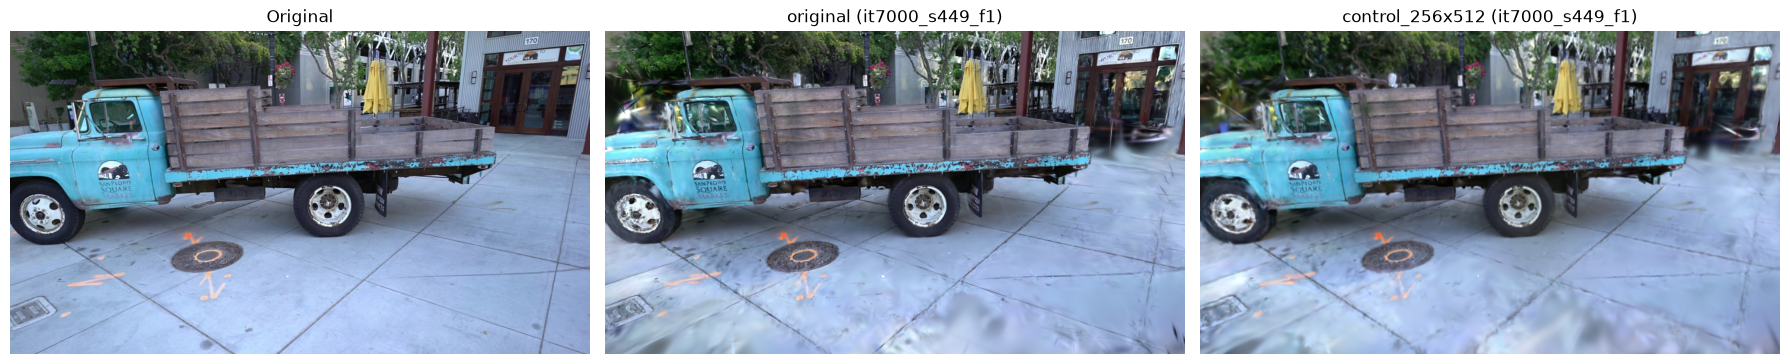

In [6]:
cfg = json.loads((RAIZ / "data/conditions" / ESCENA / "original/vistas.json").read_text())
vista = cfg["prueba"][0]
paneles = [("Original", Image.open(RAIZ / "data" / ESCENA / "images" / vista))]
for cond in CONDICIONES:
    corridas = sorted((RAIZ / "outputs" / ESCENA / cond).glob(f"it*_s{SEMILLA}_f*/renders"),
                      key=lambda p: int(p.parent.name.split("_")[0][2:]))
    if corridas:
        ruta = corridas[-1] / (Path(vista).stem + ".png")
        paneles.append((f"{cond} ({corridas[-1].parent.name})", Image.open(ruta)))

fig, ax = plt.subplots(1, len(paneles), figsize=(6 * len(paneles), 3.6))
for a, (titulo, img) in zip(ax if len(paneles) > 1 else [ax], paneles):
    a.imshow(img); a.set_title(titulo); a.axis("off")
plt.tight_layout()

**Cómo leer estos números.** Con solo 21 vistas, separadas unos 17° en una captura de 360°,
3DGS ajusta muy bien las vistas de entrenamiento, pero generaliza peor a las de prueba (régimen
de pocas vistas). Por eso el PSNR de prueba es bastante menor que el que se reporta para Truck
con las 251 vistas. Lo que interesa en este proyecto es la **diferencia** entre condiciones con
las mismas vistas, y no el valor absoluto.